In [1]:
import os
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ray
import sklearn
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

from ray import tune
from sklearn.datasets import fetch_20newsgroups
print("Python version:", sys.version)
print("Operating system:", platform.platform())
print("CPU count:", os.cpu_count())
print("Ray version:", ray.__version__)
print("Scikit-learn version:", sklearn.__version__)

Python version: 3.11.14 (main, Oct 21 2025, 18:27:30) [Clang 20.1.8 ]
Operating system: macOS-15.7.7-arm64-arm-64bit
CPU count: 12
Ray version: 2.56.0
Scikit-learn version: 1.9.0


In [2]:
# get data and prepare data
categories = [
    "comp.graphics",
    "comp.os.ms-windows.misc",
    "comp.sys.ibm.pc.hardware",
    "comp.sys.mac.hardware"
]

train_data = fetch_20newsgroups(
    subset="train",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=42
)

test_data = fetch_20newsgroups(
    subset="test",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=42
)
x_train = train_data.data
y_train = train_data.target

x_test = test_data.data
y_test = test_data.target

class_names = train_data.target_names

In [3]:
# data inspection
print("Number of training documents:", len(x_train))
print("Number of test documents:", len(x_test))
print("Number of classes:", len(class_names))

print("\nClass names:")
for label, name in enumerate(class_names):
    print(f"{label}: {name}")

Number of training documents: 2343
Number of test documents: 1560
Number of classes: 4

Class names:
0: comp.graphics
1: comp.os.ms-windows.misc
2: comp.sys.ibm.pc.hardware
3: comp.sys.mac.hardware


In [4]:
pd.Series(y_train).value_counts()
type(y_train)

numpy.ndarray

In [5]:
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "class_name": class_names,
    "train_count": train_counts.values,
    "test_count": test_counts.values
})

class_distribution

,class_name,train_count,test_count
0,comp.graphics,584,389
1,comp.os.ms-windows.misc,591,394
2,comp.sys.ibm.pc.hardware,590,392
3,comp.sys.mac.hardware,578,385


In [6]:
sample_index = 0

print("Class:", class_names[y_train[sample_index]])
print("\nDocument:")
print(x_train[sample_index][:1500])

Class: comp.sys.mac.hardware

Document:

Well, I also have an LC III.  Popping the top revealed:

	One "socket" for an additional VRAM SIMM

	One "socket" for a 72-pin RAM SIMM

	One socket for a flat-pack FPU

	A processor-direct slot (PDS) identical to the LC/LC II, but with
	an additional set of connetions to one side (for the full 32-bit
	data path that the LC/LC II lacked

That's it.  I guess a board with a PowerPC chip could be made that would fit
in the PDS, but that's the only place.


In [7]:
empty_train = sum(
    not document.strip()
    for document in x_train
)

empty_test = sum(
    not document.strip()
    for document in x_test
)

print("Empty training documents:", empty_train)
print("Empty test documents:", empty_test)

Empty training documents: 68
Empty test documents: 40


In [8]:
# build baseline model
baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer()
    ),
    (
        "classifier",
        LinearSVC(
            max_iter=5000,
            random_state=42
        )
    )
])

baseline_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_cv_scores = cross_val_score(
    baseline_model,
    x_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

print("F1 score for each fold:", baseline_cv_scores)
print("Mean CV F1:", baseline_cv_scores.mean())
print("CV standard deviation:", baseline_cv_scores.std())

F1 score for each fold: [0.77063386 0.7569958  0.74747477 0.79034872 0.74571266]
Mean CV F1: 0.7622331634239194
CV standard deviation: 0.01660857168302496


In [10]:
start_time = time.perf_counter()

baseline_model.fit(x_train, y_train)

baseline_training_time = time.perf_counter() - start_time

print(f"Baseline training time: {baseline_training_time:.3f} seconds")

Baseline training time: 0.153 seconds


In [11]:
baseline_predictions = baseline_model.predict(x_test)

print("Number of predictions:", len(baseline_predictions))
print("First 10 predictions:", baseline_predictions[:10])
print("First 10 true labels:", y_test[:10])

Number of predictions: 1560
First 10 predictions: [0 1 2 2 3 0 2 3 1 1]
First 10 true labels: [3 2 2 2 2 0 2 3 1 1]


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

baseline_precision = precision_score(
    y_test,
    baseline_predictions,
    average="macro",
    zero_division=0
)

baseline_recall = recall_score(
    y_test,
    baseline_predictions,
    average="macro",
    zero_division=0
)

baseline_test_f1 = f1_score(
    y_test,
    baseline_predictions,
    average="macro",
    zero_division=0
)

print(f"Test accuracy:        {baseline_accuracy:.4f}")
print(f"Test macro precision: {baseline_precision:.4f}")
print(f"Test macro recall:    {baseline_recall:.4f}")
print(f"Test macro F1:        {baseline_test_f1:.4f}")

Test accuracy:        0.7365
Test macro precision: 0.7365
Test macro recall:    0.7367
Test macro F1:        0.7364


In [13]:
print(
    classification_report(
        y_test,
        baseline_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

                          precision    recall  f1-score   support

           comp.graphics     0.7836    0.8098    0.7965       389
 comp.os.ms-windows.misc     0.7007    0.7132    0.7069       394
comp.sys.ibm.pc.hardware     0.7117    0.6990    0.7053       392
   comp.sys.mac.hardware     0.7500    0.7247    0.7371       385

                accuracy                         0.7365      1560
               macro avg     0.7365    0.7367    0.7364      1560
            weighted avg     0.7363    0.7365    0.7363      1560



In [14]:
baseline_results = {
    "strategy": "Baseline",
    "mean_cv_f1": baseline_cv_scores.mean(),
    "std_cv_f1": baseline_cv_scores.std(),
    "test_accuracy": baseline_accuracy,
    "test_precision": baseline_precision,
    "test_recall": baseline_recall,
    "test_f1": baseline_test_f1,
    "training_time": baseline_training_time
}

pd.DataFrame([baseline_results])

,strategy,mean_cv_f1,std_cv_f1,test_accuracy,test_precision,test_recall,test_f1,training_time
0,Baseline,0.762233,0.016609,0.736538,0.736505,0.736655,0.736444,0.152889


In [15]:
def train_model(config, x_train, y_train):
    """
    Evaluate one TF-IDF + LinearSVC hyperparameter configuration.
    """

    start_time = time.perf_counter()

    # Use exactly the same CV splits for every trial
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Build the text-classification pipeline
    model = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=tuple(config["ngram_range"]),
                min_df=config["min_df"],
                max_df=config["max_df"],
                sublinear_tf=config["sublinear_tf"]
            )
        ),
        (
            "classifier",
            LinearSVC(
                C=config["C"],
                class_weight=config["class_weight"],
                max_iter=5000,
                random_state=42
            )
        )
    ])

    # Evaluate the configuration with 5-fold CV
    cv_scores = cross_val_score(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1
    )

    trial_runtime = time.perf_counter() - start_time

    # Ray Tune will record these values
    return {
        "mean_cv_f1": float(cv_scores.mean()),
        "std_cv_f1": float(cv_scores.std()),
        "trial_runtime": float(trial_runtime)
    }

In [16]:
example_config = {
    "C": 1.0,
    "ngram_range": (1, 1),
    "min_df": 1,
    "max_df": 1.0,
    "sublinear_tf": False,
    "class_weight": None
}

example_result = train_model(
    example_config,
    x_train,
    y_train
)

example_result

{'mean_cv_f1': 0.7622331634239194,
 'std_cv_f1': 0.01660857168302496,
 'trial_runtime': 0.7381403329782188}

In [17]:
trainable_with_data = tune.with_parameters(
    train_model,
    x_train=x_train,
    y_train=y_train
)

ray_trainable = tune.with_resources(
    trainable_with_data,
    resources={"cpu": 1}
)

print("Ray trainable is ready.")

Ray trainable is ready.


In [18]:
# Grid search: tests every possible combination
grid_space = {
    "C": tune.grid_search([0.01, 0.1, 1.0, 10.0]),

    # Lists are used here; Cell 15 converts them into tuples
    "ngram_range": tune.grid_search([
        [1, 1],
        [1, 2]
    ]),

    "min_df": tune.grid_search([1, 2]),
    "sublinear_tf": tune.grid_search([False, True]),

    # Keep these fixed for now
    "max_df": 1.0,
    "class_weight": None
}


# Random search: randomly samples from these possibilities
random_space = {
    "C": tune.loguniform(0.01, 10.0),

    "ngram_range": tune.choice([
        [1, 1],
        [1, 2]
    ]),

    "min_df": tune.choice([1, 2]),
    "sublinear_tf": tune.choice([False, True]),

    "max_df": 1.0,
    "class_weight": None
}


# Bayesian search uses the same allowed space as random search.
# The difference will be how HyperOpt chooses the configurations.
bayesian_space = {
    "C": tune.loguniform(0.01, 10.0),

    "ngram_range": tune.choice([
        [1, 1],
        [1, 2]
    ]),

    "min_df": tune.choice([1, 2]),
    "sublinear_tf": tune.choice([False, True]),

    "max_df": 1.0,
    "class_weight": None
}

print("Search spaces are ready.")

Search spaces are ready.


In [19]:
grid_tuner = tune.Tuner(
    ray_trainable,

    param_space=grid_space,

    tune_config=tune.TuneConfig(
        metric="mean_cv_f1",
        mode="max",

        # Run the complete grid only once
        num_samples=1,

        # Run at most 4 trials simultaneously
        max_concurrent_trials=4
    ),

    run_config=tune.RunConfig(
        name="linear_svc_grid_search"
    )
)

grid_start_time = time.perf_counter()

grid_results = grid_tuner.fit()

grid_total_time = time.perf_counter() - grid_start_time

print(f"Total grid-search time: {grid_total_time:.2f} seconds")

2026-07-24 18:24:58,999	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to '/Users/mochixing/ray_results/linear_svc_grid_search' in 0.0066s.
2026-07-24 18:24:59,003	INFO tune.py:1039 -- Total run time: 31.88 seconds (31.01 seconds for the tuning loop).


Total grid-search time: 34.10 seconds


In [20]:
print("Successful trials:", grid_results.num_terminated)
print("Failed trials:", grid_results.num_errors)

Successful trials: 32
Failed trials: 0


In [21]:
grid_df = grid_results.get_dataframe()

grid_df[
    [
        "config/C",
        "config/ngram_range",
        "config/min_df",
        "config/sublinear_tf",
        "mean_cv_f1",
        "std_cv_f1",
        "trial_runtime"
    ]
].sort_values(
    by="mean_cv_f1",
    ascending=False
).head(10)

,config/C,config/ngram_range,config/min_df,config/sublinear_tf,mean_cv_f1,std_cv_f1,trial_runtime
26,1.0,"[1, 2]",1,True,0.771652,0.019067,3.163387
27,10.0,"[1, 2]",1,True,0.770415,0.016034,6.277945
11,10.0,"[1, 2]",1,False,0.767727,0.021831,5.929648
18,1.0,"[1, 1]",1,True,0.766188,0.011126,0.835000
10,1.0,"[1, 2]",1,False,0.764685,0.023885,3.144029
2,1.0,"[1, 1]",1,False,0.762233,0.016609,0.839773
17,0.1,"[1, 1]",1,True,0.760412,0.012675,0.750251
22,1.0,"[1, 1]",2,True,0.760133,0.009986,0.714470
30,1.0,"[1, 2]",2,True,0.759131,0.019651,1.884068
14,1.0,"[1, 2]",2,False,0.757957,0.017009,1.865154


In [22]:
best_grid_result = grid_results.get_best_result(
    metric="mean_cv_f1",
    mode="max"
)

best_grid_config = best_grid_result.config
best_grid_cv_f1 = best_grid_result.metrics["mean_cv_f1"]
best_grid_cv_std = best_grid_result.metrics["std_cv_f1"]

print("Best grid configuration:")
print(best_grid_config)

print(f"\nBest grid CV F1: {best_grid_cv_f1:.4f}")
print(f"CV standard deviation: {best_grid_cv_std:.4f}")

Best grid configuration:
{'C': 1.0, 'ngram_range': [1, 2], 'min_df': 1, 'sublinear_tf': True, 'max_df': 1.0, 'class_weight': None}

Best grid CV F1: 0.7717
CV standard deviation: 0.0191


In [23]:
random_tuner = tune.Tuner(
    ray_trainable,

    param_space=random_space,

    tune_config=tune.TuneConfig(
        metric="mean_cv_f1",
        mode="max",

        # Randomly sample 32 configurations
        num_samples=32,

        # Run at most 4 trials at the same time
        max_concurrent_trials=4
    ),

    run_config=tune.RunConfig(
        name="linear_svc_random_search"
    )
)

random_start_time = time.perf_counter()

random_results = random_tuner.fit()

random_total_time = time.perf_counter() - random_start_time

print(f"Total random-search time: {random_total_time:.2f} seconds")

2026-07-24 18:25:26,884	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to '/Users/mochixing/ray_results/linear_svc_random_search' in 0.0109s.
2026-07-24 18:25:26,888	INFO tune.py:1039 -- Total run time: 27.84 seconds (27.82 seconds for the tuning loop).


Total random-search time: 27.86 seconds


In [24]:
print("Successful trials:", random_results.num_terminated)
print("Failed trials:", random_results.num_errors)

Successful trials: 32
Failed trials: 0


In [25]:
random_df = random_results.get_dataframe()

random_df[
    [
        "config/C",
        "config/ngram_range",
        "config/min_df",
        "config/sublinear_tf",
        "mean_cv_f1",
        "std_cv_f1",
        "trial_runtime"
    ]
].sort_values(
    by="mean_cv_f1",
    ascending=False
).head(10)

,config/C,config/ngram_range,config/min_df,config/sublinear_tf,mean_cv_f1,std_cv_f1,trial_runtime
17,0.371129,"[1, 1]",1,True,0.775484,0.011548,0.792232
12,0.248853,"[1, 1]",1,True,0.772319,0.012602,0.750339
2,0.208238,"[1, 1]",1,False,0.768404,0.013372,0.721382
16,0.640267,"[1, 2]",1,True,0.768232,0.017864,2.971015
1,0.287685,"[1, 1]",2,True,0.767526,0.012571,0.629428
29,0.391557,"[1, 2]",1,True,0.766738,0.020549,2.705224
23,0.819667,"[1, 1]",1,False,0.763940,0.014972,0.860211
11,0.131958,"[1, 1]",1,True,0.762124,0.012855,0.798533
21,0.534366,"[1, 2]",2,True,0.761810,0.017885,1.784527
27,0.136057,"[1, 1]",1,False,0.760877,0.010897,0.774661


In [26]:
best_random_result = random_results.get_best_result(
    metric="mean_cv_f1",
    mode="max"
)

best_random_config = best_random_result.config
best_random_cv_f1 = best_random_result.metrics["mean_cv_f1"]
best_random_cv_std = best_random_result.metrics["std_cv_f1"]

print("Best random-search configuration:")
print(best_random_config)

print(f"\nBest random CV F1: {best_random_cv_f1:.4f}")
print(f"CV standard deviation: {best_random_cv_std:.4f}")

Best random-search configuration:
{'C': 0.37112863306345845, 'ngram_range': [1, 1], 'min_df': 1, 'sublinear_tf': True, 'max_df': 1.0, 'class_weight': None}

Best random CV F1: 0.7755
CV standard deviation: 0.0115


In [27]:
from ray.tune.search import ConcurrencyLimiter
from ray.tune.search.hyperopt import HyperOptSearch

hyperopt_search = HyperOptSearch(
    metric="mean_cv_f1",
    mode="max",

    # Start with 5 random trials before TPE begins learning
    n_initial_points=5,

    # Make the suggestions reproducible
    random_state_seed=42
)

# Allow at most 2 Bayesian trials to run simultaneously
hyperopt_search = ConcurrencyLimiter(
    hyperopt_search,
    max_concurrent=2
)

print("HyperOpt Bayesian search is ready.")

/opt/anaconda3/envs/work/lib/python3.11/site-packages/hyperopt/atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


HyperOpt Bayesian search is ready.


In [28]:
bayesian_tuner = tune.Tuner(
    ray_trainable,

    param_space=bayesian_space,

    tune_config=tune.TuneConfig(
        metric="mean_cv_f1",
        mode="max",

        search_alg=hyperopt_search,

        # Same trial budget as grid and random search
        num_samples=32
    ),

    run_config=tune.RunConfig(
        name="linear_svc_bayesian_search"
    )
)

bayesian_start_time = time.perf_counter()

bayesian_results = bayesian_tuner.fit()

bayesian_total_time = (
    time.perf_counter() - bayesian_start_time
)

print(
    f"Total Bayesian-search time: "
    f"{bayesian_total_time:.2f} seconds"
)

2026-07-24 18:25:29,414	INFO tensorboardx.py:158 -- Removed the following hyperparameter values when logging to tensorboard: {'ngram_range': (1, 1)}
2026-07-24 18:25:31,822	INFO tensorboardx.py:158 -- Removed the following hyperparameter values when logging to tensorboard: {'ngram_range': (1, 2)}
2026-07-24 18:25:32,371	INFO tensorboardx.py:158 -- Removed the following hyperparameter values when logging to tensorboard: {'ngram_range': (1, 1)}
2026-07-24 18:25:34,805	INFO tensorboardx.py:158 -- Removed the following hyperparameter values when logging to tensorboard: {'ngram_range': (1, 2)}
2026-07-24 18:25:37,119	INFO tensorboardx.py:158 -- Removed the following hyperparameter values when logging to tensorboard: {'ngram_range': (1, 2)}
2026-07-24 18:25:37,990	INFO tensorboardx.py:158 -- Removed the following hyperparameter values when logging to tensorboard: {'ngram_range': (1, 2)}
2026-07-24 18:25:41,081	INFO tensorboardx.py:158 -- Removed the following hyperparameter values when loggi

Total Bayesian-search time: 67.04 seconds


In [29]:
print(
    "Successful trials:",
    bayesian_results.num_terminated
)

print(
    "Failed trials:",
    bayesian_results.num_errors
)

Successful trials: 32
Failed trials: 0


In [30]:
bayesian_df = bayesian_results.get_dataframe()

bayesian_df[
    [
        "config/C",
        "config/ngram_range",
        "config/min_df",
        "config/sublinear_tf",
        "mean_cv_f1",
        "std_cv_f1",
        "trial_runtime"
    ]
].sort_values(
    by="mean_cv_f1",
    ascending=False
).head(10)

,config/C,config/ngram_range,config/min_df,config/sublinear_tf,mean_cv_f1,std_cv_f1,trial_runtime
18,1.427295,"(1, 2)",1,True,0.775676,0.018680,2.852469
22,1.338203,"(1, 2)",1,True,0.775266,0.018074,2.936117
29,1.275073,"(1, 2)",1,True,0.774402,0.018295,2.827194
31,2.452088,"(1, 2)",1,True,0.772719,0.018160,2.953520
14,2.135374,"(1, 2)",1,True,0.772681,0.018351,3.082727
20,1.750072,"(1, 2)",1,True,0.772671,0.017958,3.073311
19,3.332054,"(1, 2)",1,True,0.772281,0.017398,3.560891
17,3.208540,"(1, 2)",1,True,0.771840,0.017418,3.554097
27,9.710221,"(1, 2)",1,True,0.770415,0.016034,5.706817
21,8.308764,"(1, 2)",1,True,0.770415,0.016034,5.242220


In [31]:
best_bayesian_result = (
    bayesian_results.get_best_result(
        metric="mean_cv_f1",
        mode="max"
    )
)

best_bayesian_config = (
    best_bayesian_result.config
)

best_bayesian_cv_f1 = (
    best_bayesian_result.metrics["mean_cv_f1"]
)

best_bayesian_cv_std = (
    best_bayesian_result.metrics["std_cv_f1"]
)

print("Best Bayesian configuration:")
print(best_bayesian_config)

print(
    f"\nBest Bayesian CV F1: "
    f"{best_bayesian_cv_f1:.4f}"
)

print(
    f"CV standard deviation: "
    f"{best_bayesian_cv_std:.4f}"
)

Best Bayesian configuration:
{'C': 1.427294802721886, 'ngram_range': (1, 2), 'min_df': 1, 'sublinear_tf': True, 'max_df': 1.0, 'class_weight': None}

Best Bayesian CV F1: 0.7757
CV standard deviation: 0.0187


In [32]:
print("Grid columns:")
print(grid_df.columns.tolist())

print("\nRandom columns:")
print(random_df.columns.tolist())

print("\nBayesian columns:")
print(bayesian_df.columns.tolist())

Grid columns:
['mean_cv_f1', 'std_cv_f1', 'trial_runtime', 'timestamp', 'checkpoint_dir_name', 'done', 'training_iteration', 'trial_id', 'date', 'time_this_iter_s', 'time_total_s', 'pid', 'hostname', 'node_ip', 'time_since_restore', 'iterations_since_restore', 'config/C', 'config/ngram_range', 'config/min_df', 'config/sublinear_tf', 'config/max_df', 'config/class_weight', 'logdir']

Random columns:
['mean_cv_f1', 'std_cv_f1', 'trial_runtime', 'timestamp', 'checkpoint_dir_name', 'done', 'training_iteration', 'trial_id', 'date', 'time_this_iter_s', 'time_total_s', 'pid', 'hostname', 'node_ip', 'time_since_restore', 'iterations_since_restore', 'config/C', 'config/ngram_range', 'config/min_df', 'config/sublinear_tf', 'config/max_df', 'config/class_weight', 'logdir']

Bayesian columns:
['mean_cv_f1', 'std_cv_f1', 'trial_runtime', 'timestamp', 'checkpoint_dir_name', 'done', 'training_iteration', 'trial_id', 'date', 'time_this_iter_s', 'time_total_s', 'pid', 'hostname', 'node_ip', 'time_since

In [34]:
def clean_tune_results(df, strategy):
    """
    Convert a Ray Tune result DataFrame into a smaller,
    standardized trial-results table.
    """

    cleaned = df[
        [
            "config/C",
            "config/ngram_range",
            "config/min_df",
            "config/sublinear_tf",
            "config/max_df",
            "config/class_weight",
            "mean_cv_f1",
            "std_cv_f1",
            "trial_runtime"
        ]
    ].copy()

    cleaned = cleaned.rename(
        columns={
            "config/C": "C",
            "config/ngram_range": "ngram_range",
            "config/min_df": "min_df",
            "config/sublinear_tf": "sublinear_tf",
            "config/max_df": "max_df",
            "config/class_weight": "class_weight"
        }
    )

    cleaned.insert(0, "strategy", strategy)

    # Convert lists such as [1, 2] into tuples such as (1, 2)
    cleaned["ngram_range"] = cleaned["ngram_range"].apply(
        lambda value: tuple(value)
        if isinstance(value, (list, tuple))
        else value
    )

    # Number trials within each optimization strategy
    cleaned.insert(
        1,
        "trial",
        range(1, len(cleaned) + 1)
    )

    return cleaned

In [35]:
grid_clean = clean_tune_results(
    grid_df,
    "Grid"
)

random_clean = clean_tune_results(
    random_df,
    "Random"
)

bayesian_clean = clean_tune_results(
    bayesian_df,
    "Bayesian"
)

all_trials = pd.concat(
    [
        grid_clean,
        random_clean,
        bayesian_clean
    ],
    ignore_index=True
)

print("Total recorded trials:", len(all_trials))

all_trials.head()

Total recorded trials: 96


,strategy,trial,C,ngram_range,min_df,sublinear_tf,max_df,class_weight,mean_cv_f1,std_cv_f1,trial_runtime
0,Grid,1,0.01,"(1, 1)",1,False,1.0,None,0.715385,0.015199,0.688886
1,Grid,2,0.10,"(1, 1)",1,False,1.0,None,0.753219,0.012248,0.716126
2,Grid,3,1.00,"(1, 1)",1,False,1.0,None,0.762233,0.016609,0.839773
3,Grid,4,10.00,"(1, 1)",1,False,1.0,None,0.749883,0.013717,1.767928
4,Grid,5,0.01,"(1, 1)",2,False,1.0,None,0.715806,0.012219,0.588690


In [36]:
all_trials.groupby("strategy").size()

strategy
Bayesian    32
Grid        32
Random      32
dtype: int64

In [37]:
all_trials["best_score_so_far"] = (
    all_trials
    .groupby("strategy")["mean_cv_f1"]
    .cummax()
)
all_trials[
    [
        "strategy",
        "trial",
        "mean_cv_f1",
        "best_score_so_far"
    ]
].head(10)

,strategy,trial,mean_cv_f1,best_score_so_far
0,Grid,1,0.715385,0.715385
1,Grid,2,0.753219,0.753219
2,Grid,3,0.762233,0.762233
3,Grid,4,0.749883,0.762233
4,Grid,5,0.715806,0.762233
5,Grid,6,0.751084,0.762233
6,Grid,7,0.754835,0.762233
7,Grid,8,0.737034,0.762233
8,Grid,9,0.720942,0.762233
9,Grid,10,0.745499,0.762233


In [38]:
os.makedirs(
    "results",
    exist_ok=True
)

all_trials.to_csv(
    "results/all_ray_tune_trials.csv",
    index=False
)

print("Trial results saved successfully.")

Trial results saved successfully.


In [39]:
search_summary = (
    all_trials
    .groupby("strategy")
    .agg(
        number_of_trials=("trial", "count"),
        best_cv_f1=("mean_cv_f1", "max"),
        average_cv_f1=("mean_cv_f1", "mean"),
        average_trial_time=("trial_runtime", "mean"),
        total_trial_time=("trial_runtime", "sum")
    )
    .reset_index()
)

search_summary

,strategy,number_of_trials,best_cv_f1,average_cv_f1,average_trial_time,total_trial_time
0,Bayesian,32,0.775676,0.758199,2.182341,69.834914
1,Grid,32,0.771652,0.747511,1.895106,60.643394
2,Random,32,0.775484,0.750814,1.621513,51.888407


In [40]:
def build_model(config):
    """
    Build a TF-IDF + LinearSVC pipeline from a Ray Tune configuration.
    """

    model = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=tuple(config["ngram_range"]),
                min_df=config["min_df"],
                max_df=config["max_df"],
                sublinear_tf=config["sublinear_tf"]
            )
        ),
        (
            "classifier",
            LinearSVC(
                C=config["C"],
                class_weight=config["class_weight"],
                max_iter=5000,
                random_state=42
            )
        )
    ])

    return model

In [41]:
def evaluate_tuned_model(
    strategy,
    config,
    best_cv_f1,
    cv_std,
    search_time,
    x_train,
    y_train,
    x_test,
    y_test
):
    """
    Retrain one best configuration and evaluate it on the test set.
    """

    model = build_model(config)

    # Train using all training documents
    start_time = time.perf_counter()

    model.fit(x_train, y_train)

    final_fit_time = time.perf_counter() - start_time

    # Predict the untouched test documents
    predictions = model.predict(x_test)

    results = {
        "strategy": strategy,
        "mean_cv_f1": best_cv_f1,
        "std_cv_f1": cv_std,
        "test_accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "test_precision": precision_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "test_recall": recall_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "test_f1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "search_time": search_time,
        "final_fit_time": final_fit_time
    }

    return results, model, predictions

In [42]:
grid_test_results, best_grid_model, grid_predictions = (
    evaluate_tuned_model(
        strategy="Grid",
        config=best_grid_config,
        best_cv_f1=best_grid_cv_f1,
        cv_std=best_grid_cv_std,
        search_time=grid_total_time,
        x_train=x_train,
        y_train=y_train,
        x_test=x_test,
        y_test=y_test
    )
)

grid_test_results

{'strategy': 'Grid',
 'mean_cv_f1': 0.7716520385581092,
 'std_cv_f1': 0.019067112561559865,
 'test_accuracy': 0.7397435897435898,
 'test_precision': 0.7395901308815498,
 'test_recall': 0.7398890599684247,
 'test_f1': 0.7395330974139149,
 'search_time': 34.10327754204627,
 'final_fit_time': 0.5671411670045927}

In [43]:
random_test_results, best_random_model, random_predictions = (
    evaluate_tuned_model(
        strategy="Random",
        config=best_random_config,
        best_cv_f1=best_random_cv_f1,
        cv_std=best_random_cv_std,
        search_time=random_total_time,
        x_train=x_train,
        y_train=y_train,
        x_test=x_test,
        y_test=y_test
    )
)

random_test_results

{'strategy': 'Random',
 'mean_cv_f1': 0.775484430430909,
 'std_cv_f1': 0.011548005636756321,
 'test_accuracy': 0.7512820512820513,
 'test_precision': 0.7527620311246239,
 'test_recall': 0.7515527329533698,
 'test_f1': 0.7505448487918137,
 'search_time': 27.859693916980177,
 'final_fit_time': 0.1442749589914456}

In [44]:
bayesian_test_results, best_bayesian_model, bayesian_predictions = (
    evaluate_tuned_model(
        strategy="Bayesian",
        config=best_bayesian_config,
        best_cv_f1=best_bayesian_cv_f1,
        cv_std=best_bayesian_cv_std,
        search_time=bayesian_total_time,
        x_train=x_train,
        y_train=y_train,
        x_test=x_test,
        y_test=y_test
    )
)

bayesian_test_results

{'strategy': 'Bayesian',
 'mean_cv_f1': 0.7756757894769649,
 'std_cv_f1': 0.0186804555901466,
 'test_accuracy': 0.7416666666666667,
 'test_precision': 0.7416607420886298,
 'test_recall': 0.7418191193215031,
 'test_f1': 0.7416095153139335,
 'search_time': 67.03525412501767,
 'final_fit_time': 0.6505098749767058}

In [45]:
baseline_summary = {
    "strategy": "Baseline",
    "mean_cv_f1": baseline_cv_scores.mean(),
    "std_cv_f1": baseline_cv_scores.std(),
    "test_accuracy": baseline_accuracy,
    "test_precision": baseline_precision,
    "test_recall": baseline_recall,
    "test_f1": baseline_test_f1,

    # No hyperparameter search was performed
    "search_time": 0.0,

    "final_fit_time": baseline_training_time
}

In [46]:
final_summary = pd.DataFrame([
    baseline_summary,
    grid_test_results,
    random_test_results,
    bayesian_test_results
])

final_summary = final_summary.sort_values(
    by="test_f1",
    ascending=False
).reset_index(drop=True)

final_summary

,strategy,mean_cv_f1,std_cv_f1,test_accuracy,test_precision,test_recall,test_f1,search_time,final_fit_time
0,Random,0.775484,0.011548,0.751282,0.752762,0.751553,0.750545,27.859694,0.144275
1,Bayesian,0.775676,0.018680,0.741667,0.741661,0.741819,0.741610,67.035254,0.650510
2,Grid,0.771652,0.019067,0.739744,0.739590,0.739889,0.739533,34.103278,0.567141
3,Baseline,0.762233,0.016609,0.736538,0.736505,0.736655,0.736444,0.000000,0.152889


In [47]:
display_columns = [
    "strategy",
    "mean_cv_f1",
    "std_cv_f1",
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "search_time",
    "final_fit_time"
]

final_summary[display_columns].round(4)

,strategy,mean_cv_f1,std_cv_f1,test_accuracy,test_precision,test_recall,test_f1,search_time,final_fit_time
0,Random,0.7755,0.0115,0.7513,0.7528,0.7516,0.7505,27.8597,0.1443
1,Bayesian,0.7757,0.0187,0.7417,0.7417,0.7418,0.7416,67.0353,0.6505
2,Grid,0.7717,0.0191,0.7397,0.7396,0.7399,0.7395,34.1033,0.5671
3,Baseline,0.7622,0.0166,0.7365,0.7365,0.7367,0.7364,0.0000,0.1529


In [48]:
final_summary.to_csv(
    "results/final_model_summary.csv",
    index=False
)

print("Final model summary saved successfully.")

Final model summary saved successfully.


In [49]:
os.makedirs("figures", exist_ok=True)

print("Figures folder is ready.")

Figures folder is ready.


In [50]:
def create_history_dataframe(df, strategy):
    history = df.copy()

    # Put trials in completion order when possible
    if "timestamp" in history.columns:
        history = history.sort_values("timestamp")
    elif "date" in history.columns:
        history = history.sort_values("date")

    history = history.reset_index(drop=True)

    history["strategy"] = strategy
    history["trial"] = range(1, len(history) + 1)
    history["best_score_so_far"] = (
        history["mean_cv_f1"].cummax()
    )

    return history[
        [
            "strategy",
            "trial",
            "mean_cv_f1",
            "best_score_so_far"
        ]
    ]


grid_history = create_history_dataframe(
    grid_df,
    "Grid"
)

random_history = create_history_dataframe(
    random_df,
    "Random"
)

bayesian_history = create_history_dataframe(
    bayesian_df,
    "Bayesian"
)

optimization_history = pd.concat(
    [
        grid_history,
        random_history,
        bayesian_history
    ],
    ignore_index=True
)

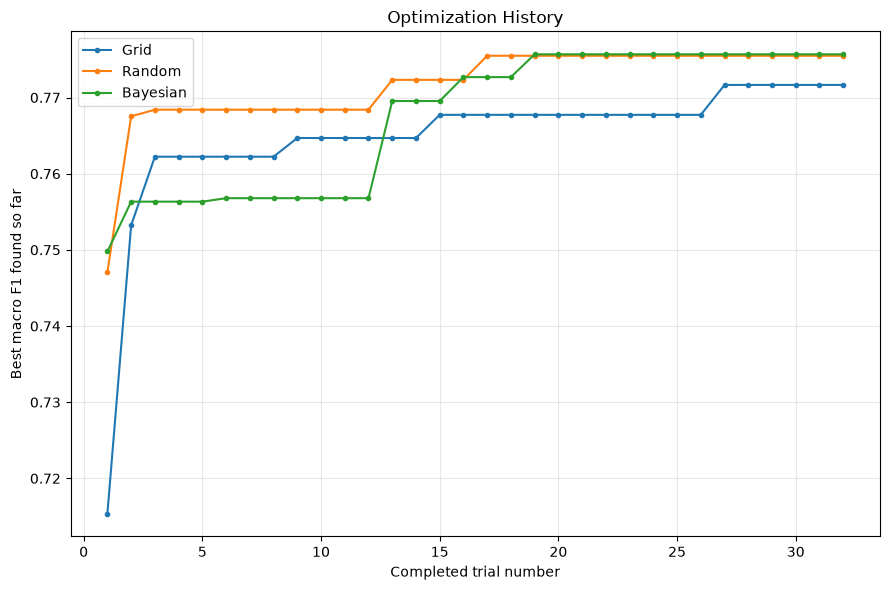

In [51]:
plt.figure(figsize=(9, 6))

for strategy in [
    "Grid",
    "Random",
    "Bayesian"
]:
    strategy_data = optimization_history[
        optimization_history["strategy"] == strategy
    ]

    plt.plot(
        strategy_data["trial"],
        strategy_data["best_score_so_far"],
        marker="o",
        markersize=3,
        label=strategy
    )

plt.xlabel("Completed trial number")
plt.ylabel("Best macro F1 found so far")
plt.title("Optimization History")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/optimization_history.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

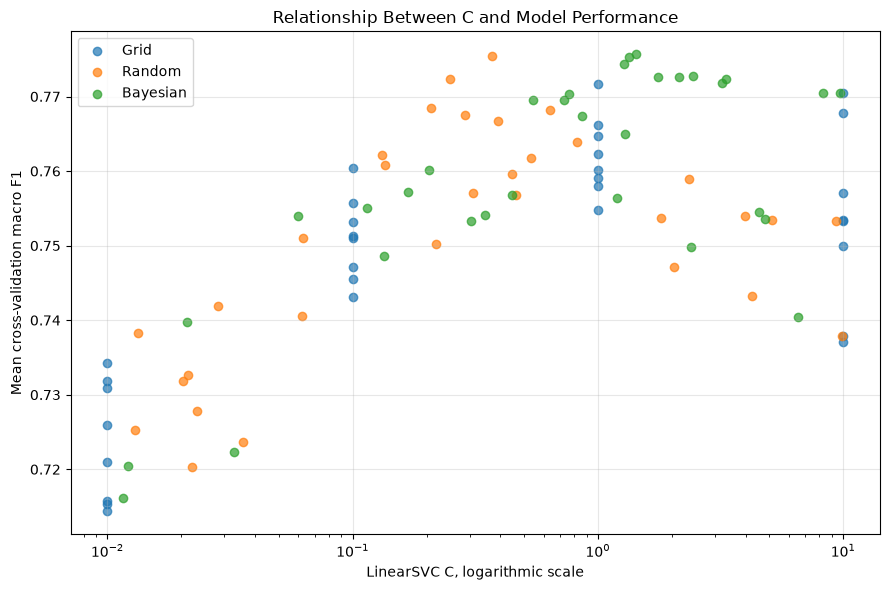

In [52]:
plt.figure(figsize=(9, 6))

for strategy in [
    "Grid",
    "Random",
    "Bayesian"
]:
    strategy_data = all_trials[
        all_trials["strategy"] == strategy
    ]

    plt.scatter(
        strategy_data["C"],
        strategy_data["mean_cv_f1"],
        label=strategy,
        alpha=0.7
    )

plt.xscale("log")
plt.xlabel("LinearSVC C, logarithmic scale")
plt.ylabel("Mean cross-validation macro F1")
plt.title("Relationship Between C and Model Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/C_vs_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
ngram_plot_data = all_trials.copy()

ngram_plot_data["ngram_label"] = (
    ngram_plot_data["ngram_range"].astype(str)
)

ngram_summary = (
    ngram_plot_data
    .groupby(
        [
            "ngram_label",
            "strategy"
        ]
    )["mean_cv_f1"]
    .mean()
    .unstack()
)

ngram_summary

strategy,Bayesian,Grid,Random
ngram_label,,,
"(1, 1)",0.752734,0.745995,0.754499
"(1, 2)",0.760020,0.749028,0.747562


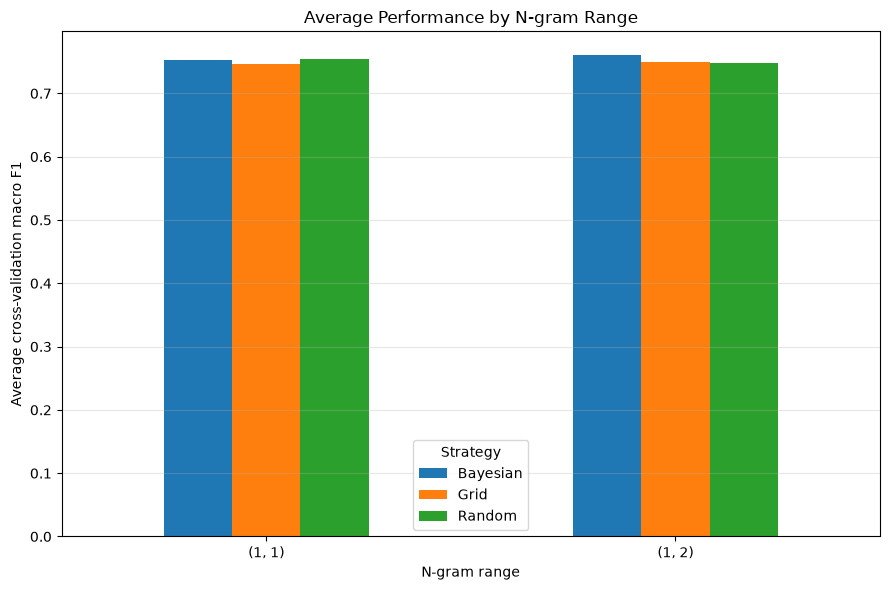

In [54]:
ngram_summary.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.xlabel("N-gram range")
plt.ylabel("Average cross-validation macro F1")
plt.title("Average Performance by N-gram Range")
plt.xticks(rotation=0)
plt.legend(title="Strategy")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/ngram_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

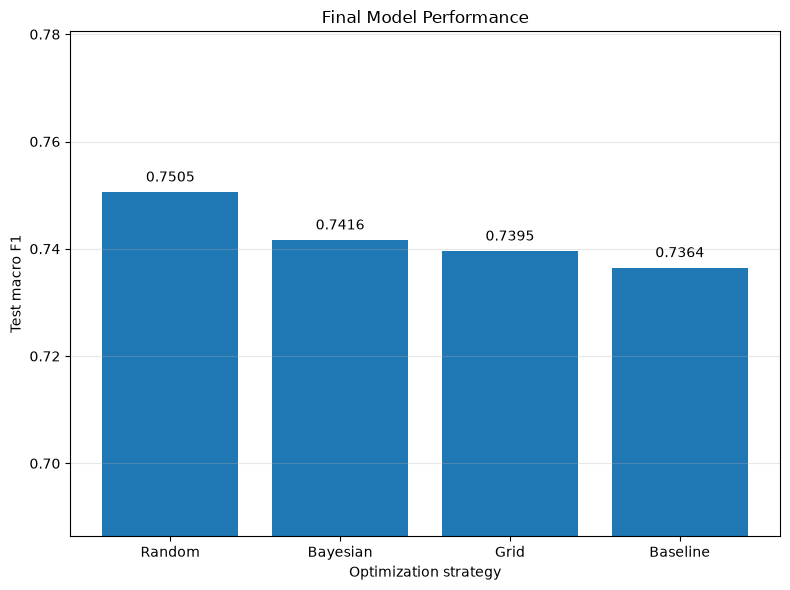

In [55]:
plot_summary = final_summary.sort_values(
    "test_f1",
    ascending=False
)

plt.figure(figsize=(8, 6))

bars = plt.bar(
    plot_summary["strategy"],
    plot_summary["test_f1"]
)

plt.xlabel("Optimization strategy")
plt.ylabel("Test macro F1")
plt.title("Final Model Performance")
plt.ylim(
    max(0, plot_summary["test_f1"].min() - 0.05),
    min(1, plot_summary["test_f1"].max() + 0.03)
)

for bar, score in zip(
    bars,
    plot_summary["test_f1"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.002,
        f"{score:.4f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
search_time_summary = pd.DataFrame({
    "strategy": [
        "Grid",
        "Random",
        "Bayesian"
    ],
    "search_time": [
        grid_total_time,
        random_total_time,
        bayesian_total_time
    ]
})

search_time_summary

,strategy,search_time
0,Grid,34.103278
1,Random,27.859694
2,Bayesian,67.035254


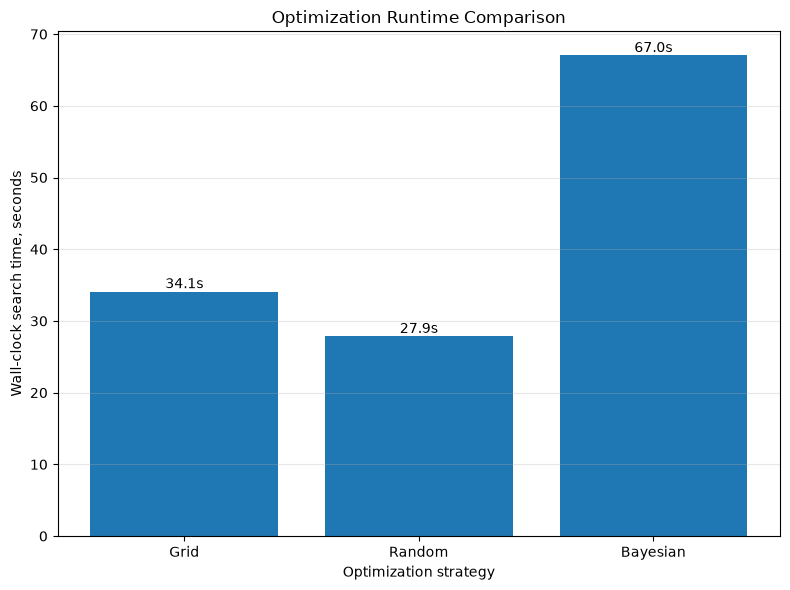

In [57]:
plt.figure(figsize=(8, 6))

bars = plt.bar(
    search_time_summary["strategy"],
    search_time_summary["search_time"]
)

plt.xlabel("Optimization strategy")
plt.ylabel("Wall-clock search time, seconds")
plt.title("Optimization Runtime Comparison")

for bar, runtime in zip(
    bars,
    search_time_summary["search_time"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{runtime:.1f}s",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/search_time_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
predictions_by_strategy = {
    "Baseline": baseline_predictions,
    "Grid": grid_predictions,
    "Random": random_predictions,
    "Bayesian": bayesian_predictions
}

best_strategy = final_summary.iloc[0]["strategy"]

best_predictions = predictions_by_strategy[
    best_strategy
]

print("Best strategy:", best_strategy)
print(
    "Best test F1:",
    final_summary.iloc[0]["test_f1"]
)

Best strategy: Random
Best test F1: 0.7505448487918137


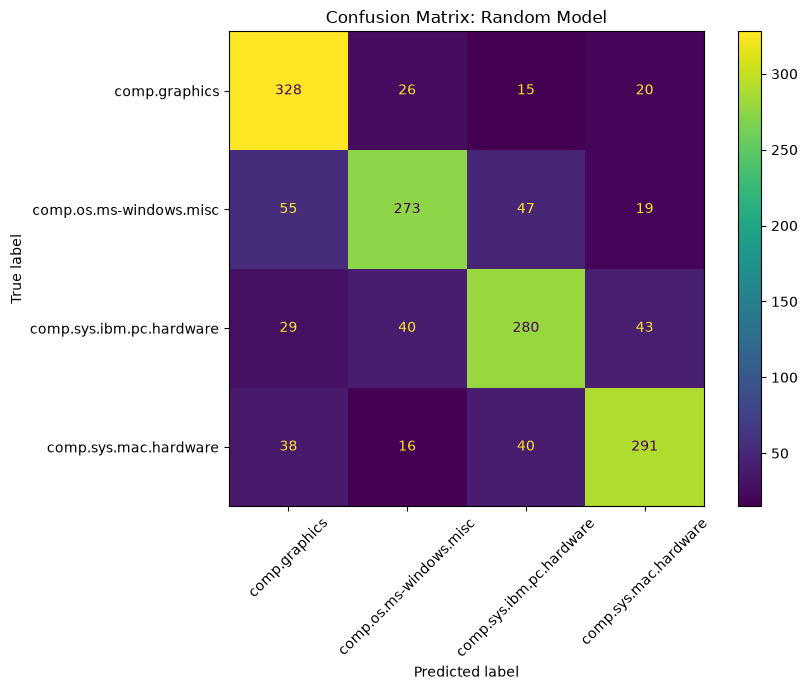

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=class_names,
    xticks_rotation=45,
    values_format="d"
)

display.figure_.set_size_inches(9, 7)
display.ax_.set_title(
    f"Confusion Matrix: {best_strategy} Model"
)

display.figure_.tight_layout()

display.figure_.savefig(
    "figures/best_model_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
print("Saved figure files:")

for filename in sorted(
    os.listdir("figures")
):
    print(filename)

Saved figure files:
C_vs_performance.png
best_model_confusion_matrix.png
final_model_comparison.png
ngram_performance.png
optimization_history.png
search_time_comparison.png


In [61]:
best_row = final_summary.loc[
    final_summary["test_f1"].idxmax()
]

best_strategy = best_row["strategy"]
best_test_f1 = best_row["test_f1"]
best_cv_f1 = best_row["mean_cv_f1"]

baseline_f1 = baseline_summary["test_f1"]

absolute_improvement = best_test_f1 - baseline_f1
percentage_improvement = (
    absolute_improvement / baseline_f1
) * 100

print("Best strategy:", best_strategy)
print(f"Best CV macro F1: {best_cv_f1:.4f}")
print(f"Best test macro F1: {best_test_f1:.4f}")
print(f"Baseline test macro F1: {baseline_f1:.4f}")
print(f"Absolute improvement: {absolute_improvement:.4f}")
print(f"Relative improvement: {percentage_improvement:.2f}%")

Best strategy: Random
Best CV macro F1: 0.7755
Best test macro F1: 0.7505
Baseline test macro F1: 0.7364
Absolute improvement: 0.0141
Relative improvement: 1.91%


In [62]:
strategy_comparison = final_summary[
    [
        "strategy",
        "mean_cv_f1",
        "test_f1",
        "test_accuracy",
        "search_time",
        "final_fit_time"
    ]
].copy()

strategy_comparison = strategy_comparison.sort_values(
    by="test_f1",
    ascending=False
).reset_index(drop=True)

strategy_comparison.round(4)

,strategy,mean_cv_f1,test_f1,test_accuracy,search_time,final_fit_time
0,Random,0.7755,0.7505,0.7513,27.8597,0.1443
1,Bayesian,0.7757,0.7416,0.7417,67.0353,0.6505
2,Grid,0.7717,0.7395,0.7397,34.1033,0.5671
3,Baseline,0.7622,0.7364,0.7365,0.0000,0.1529


In [63]:
best_configurations = {
    "Grid": best_grid_config,
    "Random": best_random_config,
    "Bayesian": best_bayesian_config
}

for strategy, config in best_configurations.items():
    print(f"\n{strategy} best configuration:")

    for parameter, value in config.items():
        print(f"  {parameter}: {value}")


Grid best configuration:
  C: 1.0
  ngram_range: [1, 2]
  min_df: 1
  sublinear_tf: True
  max_df: 1.0
  class_weight: None

Random best configuration:
  C: 0.37112863306345845
  ngram_range: [1, 1]
  min_df: 1
  sublinear_tf: True
  max_df: 1.0
  class_weight: None

Bayesian best configuration:
  C: 1.427294802721886
  ngram_range: (1, 2)
  min_df: 1
  sublinear_tf: True
  max_df: 1.0
  class_weight: None


In [64]:
best_configs_df = pd.DataFrame([
    {
        "strategy": "Grid",
        **best_grid_config,
        "best_cv_f1": best_grid_cv_f1,
        "test_f1": grid_test_results["test_f1"]
    },
    {
        "strategy": "Random",
        **best_random_config,
        "best_cv_f1": best_random_cv_f1,
        "test_f1": random_test_results["test_f1"]
    },
    {
        "strategy": "Bayesian",
        **best_bayesian_config,
        "best_cv_f1": best_bayesian_cv_f1,
        "test_f1": bayesian_test_results["test_f1"]
    }
])

best_configs_df

,strategy,C,ngram_range,min_df,sublinear_tf,max_df,class_weight,best_cv_f1,test_f1
0,Grid,1.000000,"[1, 2]",1,True,1.0,None,0.771652,0.739533
1,Random,0.371129,"[1, 1]",1,True,1.0,None,0.775484,0.750545
2,Bayesian,1.427295,"(1, 2)",1,True,1.0,None,0.775676,0.741610


In [65]:
best_configs_df.to_csv(
    "results/best_configurations.csv",
    index=False
)

print("Best configurations saved.")

Best configurations saved.


In [66]:
parameter_summary = (
    all_trials
    .groupby(
        [
            "ngram_range",
            "min_df",
            "sublinear_tf"
        ]
    )
    .agg(
        average_cv_f1=("mean_cv_f1", "mean"),
        best_cv_f1=("mean_cv_f1", "max"),
        number_of_trials=("mean_cv_f1", "count")
    )
    .reset_index()
    .sort_values(
        "average_cv_f1",
        ascending=False
    )
)

parameter_summary.head(10)

,ngram_range,min_df,sublinear_tf,average_cv_f1,best_cv_f1,number_of_trials
5,"(1, 2)",1,True,0.763419,0.775676,24
1,"(1, 1)",1,True,0.760485,0.775484,13
4,"(1, 2)",1,False,0.750864,0.767727,7
3,"(1, 1)",2,True,0.747719,0.767526,10
0,"(1, 1)",1,False,0.746911,0.768404,9
7,"(1, 2)",2,True,0.745885,0.761810,8
6,"(1, 2)",2,False,0.743794,0.757957,18
2,"(1, 1)",2,False,0.741368,0.754835,7


In [67]:
print("Although Bayesian optimization achieved the highest cross-validation score, Random Search produced the best test-set performance and required the least search time. Therefore, Random Search was the most effective strategy in this experiment.")

Although Bayesian optimization achieved the highest cross-validation score, Random Search produced the best test-set performance and required the least search time. Therefore, Random Search was the most effective strategy in this experiment.
